In [ ]:
import kagglehub
from pathlib import Path

path = kagglehub.dataset_download("pavansanagapati/images-dataset")

print("Path to dataset files:", path)

# Convert dataset path to Path object
dataset_path = Path(path)

# Display the contents of the dataset directory
print("\nDataset contents:")
for item in dataset_path.iterdir():
    print(item.name)


100%|██████████| 1.01G/1.01G [00:10<00:00, 103MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/pavansanagapati/images-dataset/versions/1

Dataset contents:
data


In [ ]:
from pathlib import Path
from collections import Counter

# Define the dataset directory
data_folder = Path(path) / "data"

print("Dataset directory:", data_folder)
print("\nSubfolders:")

# Display all subfolders
for folder in sorted(data_folder.rglob("*")):
    if folder.is_dir():
        print(folder.relative_to(data_folder))

# Count image files by extension
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    file for file in data_folder.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("\nTotal images:", len(image_files))

# Display image distribution by folder
folder_counts = Counter(
    file.parent.name for file in image_files
)

print("\nImages per folder:")
for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

Dataset directory: /root/.cache/kagglehub/datasets/pavansanagapati/images-dataset/versions/1/data

Subfolders:
bike
cars
cats
data
data/bike
data/cars
data/cats
data/dogs
data/flowers
data/horses
data/human
dogs
flowers
horses
human

Total images: 3606

Images per folder:
bike: 730
cars: 840
cats: 404
dogs: 404
flowers: 420
horses: 404
human: 404


In [ ]:
from torchvision import transforms

# Resize images and apply augmentation
size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

In [ ]:
# Split dataset into training, validation and testing
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
from torchvision import datasets
from pathlib import Path

# Define dataset folder path
train_folder = Path(path) / "data"

# Create initial dataset to get targets for stratified split
base_dataset = datasets.ImageFolder(train_folder)

all_indices = np.arange(len(base_dataset))
all_targets = np.array(base_dataset.targets)

train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    stratify=all_targets,
    random_state=42
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    stratify=all_targets[temp_indices],
    random_state=42
)

# Create datasets with appropriate transformations
train_data = Subset(
    datasets.ImageFolder(train_folder, transform=train_transform),
    train_indices
)

val_data = Subset(
    datasets.ImageFolder(train_folder, transform=val_transform),
    val_indices
)

test_data = Subset(
    datasets.ImageFolder(train_folder, transform=val_transform),
    test_indices
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

Training images: 2524
Validation images: 541
Test images: 541


In [ ]:
# Set training hyperparameters
from torch.utils.data import DataLoader

batch_size = 32
learning_rate = 1e-3
epoch_number = 10

# Create DataLoaders
trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(trn_dl))
print("Validation batches:", len(val_dl))
print("Test batches:", len(test_dl))

Training batches: 79
Validation batches: 17
Test batches: 17


In [ ]:
# Define CNN, loss function and optimizer
from torch.optim import Adam

def get_model():

    model = nn.Sequential(
        # Feature extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 6 * 6, 256),
        nn.ReLU(),
        nn.Linear(256, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()

    optimizer = Adam(
        model.parameters(),
        lr=learning_rate
    )

    return model, loss_fn, optimizer

In [ ]:
import torch

# Train CNN for one epoch
def train_one_epoch(data_loader, model, loss_fn, optimizer):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for x, y in data_loader:

        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        prediction = model(x)

        batch_loss = loss_fn(prediction, y)

        batch_loss.backward()
        optimizer.step()

        total_loss += batch_loss.item() * y.size(0)

        total_correct += (
            prediction.argmax(dim=1) == y
        ).sum().item()

        total_images += y.size(0)

    return (
        total_loss / total_images,
        total_correct / total_images
    )


# Evaluate model
@torch.no_grad()
def validation(data_loader, model, loss_fn):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for x, y in data_loader:

        x, y = x.to(device), y.to(device)

        prediction = model(x)

        batch_loss = loss_fn(prediction, y)

        total_loss += batch_loss.item() * y.size(0)

        total_correct += (
            prediction.argmax(dim=1) == y
        ).sum().item()

        total_images += y.size(0)

    return (
        total_loss / total_images,
        total_correct / total_images
    )

In [ ]:
# Create CNN and display architecture
%pip -q install torchsummary

import torch
import torch.nn as nn
from torchsummary import summary

# Define missing variables
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(base_dataset.classes) if 'base_dataset' in globals() else 7

# Ensure nn is available inside yrACLzAWsxMp's environment by registering it globally
import sys
sys.modules['__main__'].nn = nn
sys.modules['__main__'].device = device
sys.modules['__main__'].num_classes = num_classes

model, loss_fn, optimizer = get_model()

summary(
    model,
    input_size=(3, 32, 32),
    device=str(device)
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 8]           2,056
Total params: 1,257,608
Trainable params: 1,257,608
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.80
Estimat

In [ ]:
# Train CNN and record performance
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):

    epoch_loss, epoch_accuracy = train_one_epoch(
        trn_dl,
        model,
        loss_fn,
        optimizer
    )

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(
        val_dl,
        model,
        loss_fn
    )

    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(
        f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f}"
        f" | Train Accuracy: {epoch_accuracy:.2%}"
        f" | Val Loss: {v_loss:.4f}"
        f" | Val Accuracy: {v_acc:.2%}"
    )

Epoch [1/10] | Train Loss: 1.6611 | Train Accuracy: 49.45% | Val Loss: 1.5066 | Val Accuracy: 49.91%
Epoch [2/10] | Train Loss: 1.4796 | Train Accuracy: 49.60% | Val Loss: 1.3843 | Val Accuracy: 49.17%
Epoch [3/10] | Train Loss: 1.4034 | Train Accuracy: 49.48% | Val Loss: 1.3748 | Val Accuracy: 48.43%
Epoch [4/10] | Train Loss: 1.3364 | Train Accuracy: 49.60% | Val Loss: 1.2954 | Val Accuracy: 46.77%
Epoch [5/10] | Train Loss: 1.2994 | Train Accuracy: 48.89% | Val Loss: 1.3085 | Val Accuracy: 47.50%
Epoch [6/10] | Train Loss: 1.2625 | Train Accuracy: 48.57% | Val Loss: 1.2321 | Val Accuracy: 47.69%
Epoch [7/10] | Train Loss: 1.2472 | Train Accuracy: 48.38% | Val Loss: 1.2696 | Val Accuracy: 46.95%
Epoch [8/10] | Train Loss: 1.1913 | Train Accuracy: 49.45% | Val Loss: 1.2240 | Val Accuracy: 49.72%
Epoch [9/10] | Train Loss: 1.1521 | Train Accuracy: 49.88% | Val Loss: 1.2096 | Val Accuracy: 44.18%
Epoch [10/10] | Train Loss: 1.1351 | Train Accuracy: 50.00% | Val Loss: 1.2044 | Val Accura

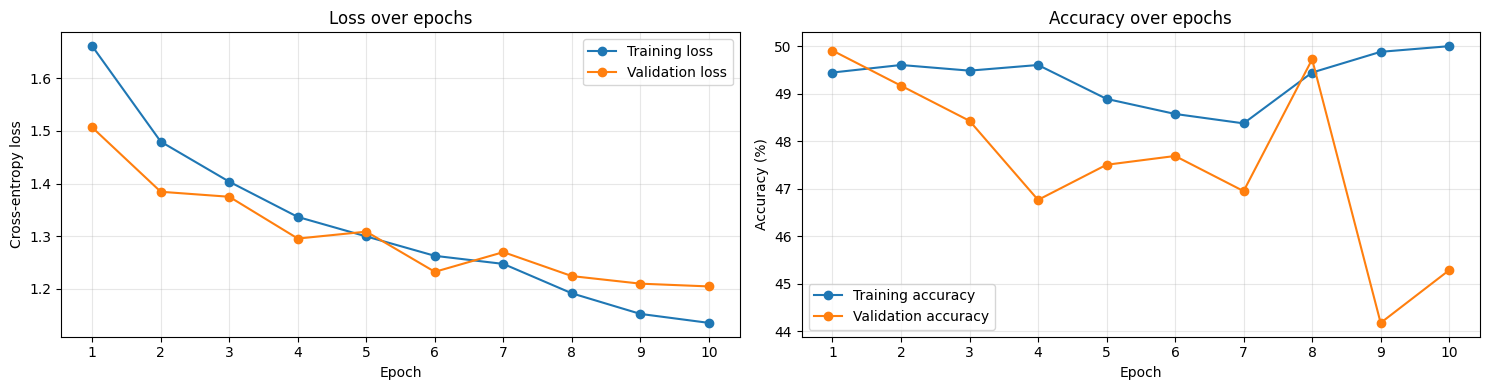

In [ ]:
# Plot loss and accuracy
import matplotlib.pyplot as plt

epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(15, 4))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(epochs, train_losses, marker="o", label="Training loss")
plt.plot(epochs, val_losses, marker="o", label="Validation loss")

plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    np.array(train_accuracies) * 100,
    marker="o",
    label="Training accuracy"
)

plt.plot(
    epochs,
    np.array(val_accuracies) * 100,
    marker="o",
    label="Validation accuracy"
)

plt.title("Accuracy over epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Measure test loss and accuracy
test_loss, test_acc = validation(
    test_dl,
    model,
    loss_fn
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2%}")

Test Loss: 2.0938
Test Accuracy: 5.55%


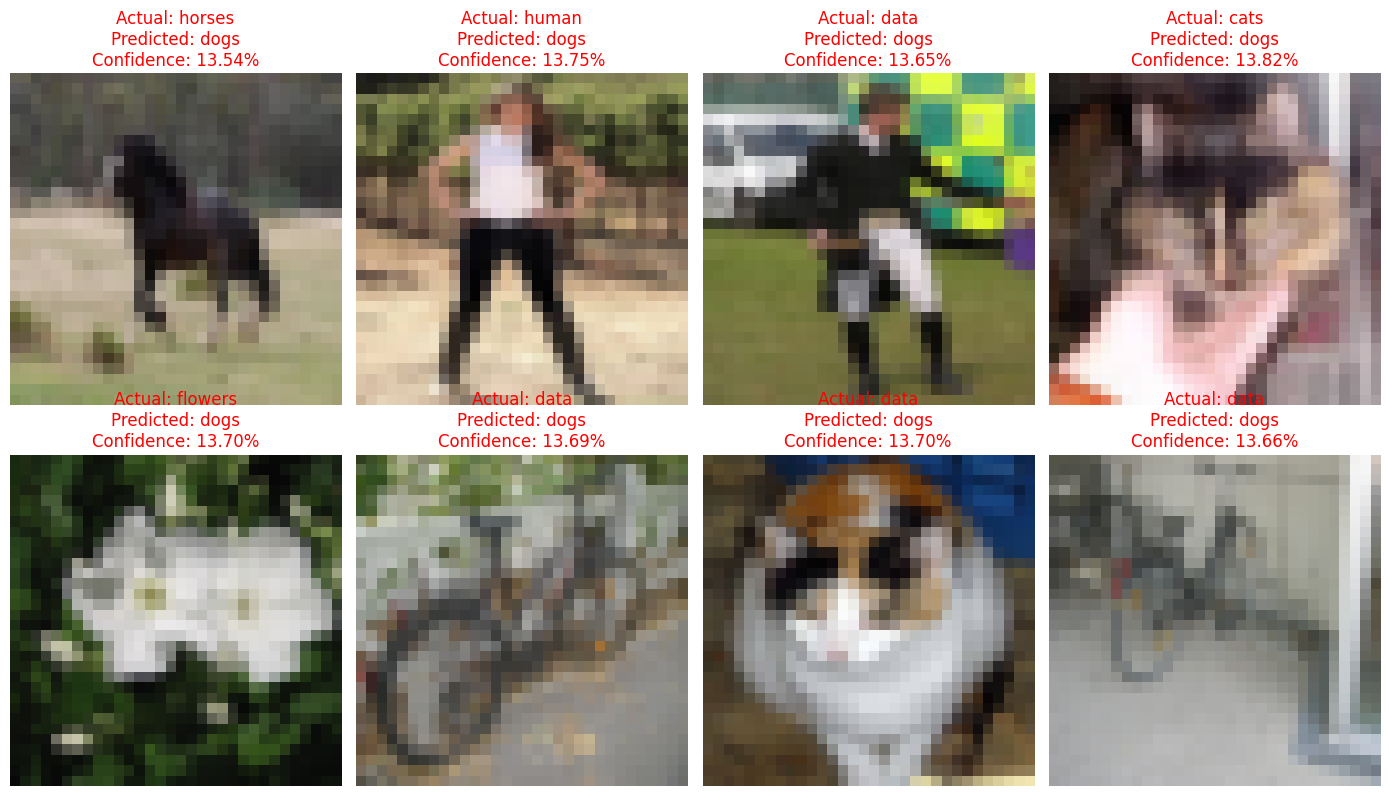

In [26]:
# Display sample test images with CNN predictions

import matplotlib.pyplot as plt
import torch

model.eval()

# Define class_names using the classes available in the kernel
class_names = classes if 'classes' in globals() else base_dataset.classes

plt.figure(figsize=(14, 8))

for i in range(8):

    test_img, label = test_data[i]

    img = test_img.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img)
        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = probabilities.max(dim=1)

    predicted_class = class_names[predicted.item()]
    actual_class = class_names[label]

    plt.subplot(2, 4, i + 1)

    plt.imshow(test_img.permute(1, 2, 0))

    color = "green" if predicted_class == actual_class else "red"

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence.item():.2%}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
# Save trained CNN weights and class information
from pathlib import Path

weights_path = Path("CNN_Image_Classification.pth")

# Retrieve classes from the base dataset
classes = base_dataset.classes if 'base_dataset' in globals() else []

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "classes": classes,
        "image_size": size
    },
    weights_path
)

print(f"Saved: {weights_path.name}")

print(
    f"File size: "
    f"{weights_path.stat().st_size / 1_000_000:.2f} MB"
)

Saved: CNN_Image_Classification.pth
File size: 5.03 MB
